In [6]:
from datasets import load_dataset

ds = load_dataset("openai/gsm8k", "socratic")

In [7]:
for i in range(5):
    print(ds["train"][i])

{'question': 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?', 'answer': 'How many clips did Natalia sell in May? ** Natalia sold 48/2 = <<48/2=24>>24 clips in May.\nHow many clips did Natalia sell altogether in April and May? ** Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.\n#### 72'}
{'question': 'Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?', 'answer': 'How much does Weng earn per minute? ** Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.\nHow much did Weng earn? ** Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.\n#### 10'}
{'question': 'Betty is saving money for a new wallet which costs $100. Betty has only half of the money she needs. Her parents decided to give her $15 for that purpose, and her grandparents twice as much as her parents. How much more money does Betty 

In [8]:
# 将数据集加载到本地
# 遍历数据集字典中的每一个拆分 (train, test 等)
for split_name, split_dataset in ds.items():
    # 默认就是 JSONL 格式，文件名以 .jsonl 结尾更清晰
    output_path = f"./gsm8k_dataset/{split_name}.jsonl"
    split_dataset.to_json(output_path)
    print(f"已保存: {output_path}")

Creating json from Arrow format:   0%|          | 0/8 [00:00<?, ?ba/s]

已保存: ./gsm8k_dataset/train.jsonl


Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

已保存: ./gsm8k_dataset/test.jsonl



===== train  (n=7473) =====
有注解的题目比例         : 98.7%
注解总数 / 平均每题      : 23716 / 3.17
result 无法解析的比例    : 0.00%
无父节点的注解比例(断链) : 44.82%
数值匹配有歧义的连接占比 : 2.45%
深度 d   : mean=2.65 min=0 p25=2 p50=3 p75=3 p95=4 max=8
工作量 W : mean=3.17 max=9
d 的分布 : {0: 95, 1: 578, 2: 2995, 3: 2429, 4: 1002, 5: 308, 6: 52, 7: 10, 8: 4}
两种连线规则下 d 的 Spearman 相关: 0.999
corr(d, W)            : 0.844
corr(d, 题目长度)     : 0.322
答案类型分布          : {'非负': 7375, '含负号': 3} | 含小数点: 0

===== test  (n=1319) =====
有注解的题目比例         : 98.6%
注解总数 / 平均每题      : 4282 / 3.25
result 无法解析的比例    : 0.02%
无父节点的注解比例(断链) : 44.11%
数值匹配有歧义的连接占比 : 2.80%
深度 d   : mean=2.69 min=0 p25=2 p50=3 p75=3 p95=4 max=6
工作量 W : mean=3.25 max=8
d 的分布 : {0: 18, 1: 91, 2: 521, 3: 416, 4: 208, 5: 56, 6: 9}
两种连线规则下 d 的 Spearman 相关: 0.999
corr(d, W)            : 0.834
corr(d, 题目长度)     : 0.245
答案类型分布          : {'非负': 1299, '含负号': 2} | 含小数点: 0


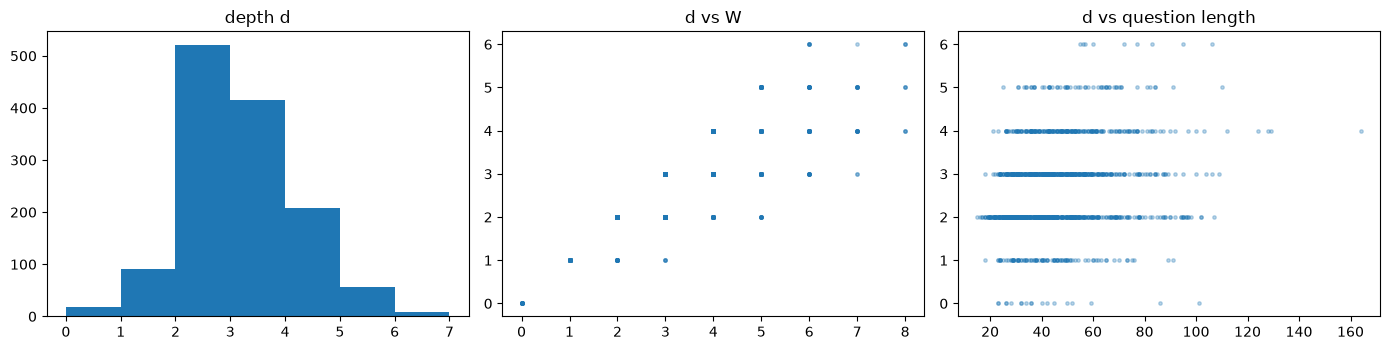

In [9]:
import json, re, sys
import numpy as np, pandas as pd
from collections import defaultdict

NUM = r"\d+(?:\.\d+)?"
ANN = re.compile(r"<<(.+?)=(.+?)>>")
FINAL = re.compile(r"####\s*(.+?)\s*$", re.M)

def tofloat(s):
    s = s.strip().replace(",", "").replace("$", "")
    try:
        return round(float(s), 6)
    except Exception:
        return None

def load(path):
    txt = open(path, encoding="utf-8").read().strip()
    if txt.lstrip().startswith("["):
        return pd.DataFrame(json.loads(txt))
    return pd.DataFrame([json.loads(l) for l in txt.splitlines() if l.strip()])

def parse_anns(sol):
    """返回注解列表: {expr, res, nums}"""
    out = []
    for m in ANN.finditer(sol):
        expr, res = m.group(1), m.group(2)
        out.append({
            "res":  tofloat(res),
            "nums": [n for n in (tofloat(x) for x in re.findall(NUM, expr)) if n is not None],
        })
    return out

def depths(anns, rule="recent"):
    """按数值相等连边，返回每个注解的深度、父节点、歧义连接数"""
    val2idx = defaultdict(list)
    parents, amb = [], 0
    for i, a in enumerate(anns):
        ps = set()
        for v in a["nums"]:
            cand = [j for j in val2idx.get(v, []) if j < i]
            if cand:
                if len(cand) > 1:
                    amb += 1
                ps.add(max(cand)) if rule == "recent" else ps.update(cand)
        parents.append(ps)
        if a["res"] is not None:
            val2idx[a["res"]].append(i)
    dep = []
    for i in range(len(anns)):
        dep.append(1 + max([dep[j] for j in parents[i]], default=0))
    return dep, parents, amb

def analyse(df, name):
    rows, bad_res, n_ann_total, n_ann_no_parent, amb_total = [], 0, 0, 0, 0
    for _, r in df.iterrows():
        sol = str(r["answer"])          # 这里 df 的 answer 是解答全文，没问题
        anns = parse_anns(sol)
        n = len(anns)
        if n == 0:
            rows.append(dict(d=0, W=0, d_all=0, no_parent=0, n_ann=0, final=None))
            continue
        d1, par, amb = depths(anns, "recent")
        d2, _,   _   = depths(anns, "all")
        bad_res += sum(1 for a in anns if a["res"] is None)
        n_ann_total += n
        n_ann_no_parent += sum(1 for p in par if not p)
        amb_total += amb
        m = FINAL.search(sol)
        rows.append(dict(
            d=max(d1), W=n, d_all=max(d2),
            no_parent=sum(1 for p in par if not p),
            n_ann=n,
            final=(m.group(1) if m else None),   # ← 改名
        ))
    aug = pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
    aug["q_len"] = aug["question"].str.split().str.len()

    print(f"\n===== {name}  (n={len(df)}) =====")
    print(f"有注解的题目比例         : {(aug.n_ann>0).mean():.1%}")
    print(f"注解总数 / 平均每题      : {n_ann_total} / {aug.n_ann.mean():.2f}")
    print(f"result 无法解析的比例    : {bad_res/max(n_ann_total,1):.2%}")
    print(f"无父节点的注解比例(断链) : {n_ann_no_parent/max(n_ann_total,1):.2%}")
    print(f"数值匹配有歧义的连接占比 : {amb_total/max(n_ann_total,1):.2%}")
    print(f"深度 d   : mean={aug.d.mean():.2f} min={aug.d.min()} "
          f"p25={aug.d.quantile(.25):.0f} p50={aug.d.median():.0f} "
          f"p75={aug.d.quantile(.75):.0f} p95={aug.d.quantile(.95):.0f} max={aug.d.max()}")
    print(f"工作量 W : mean={aug.W.mean():.2f} max={aug.W.max()}")
    print("d 的分布 :", aug.d.value_counts().sort_index().to_dict())
    print(f"两种连线规则下 d 的 Spearman 相关: "
          f"{aug[['d','d_all']].corr(method='spearman').iloc[0,1]:.3f}")
    print(f"corr(d, W)            : {aug[['d','W']].corr(method='spearman').iloc[0,1]:.3f}")
    print(f"corr(d, 题目长度)     : {aug[['d','q_len']].corr(method='spearman').iloc[0,1]:.3f}")
    fa = aug["final"].dropna()                   # ← 用 final
    print("答案类型分布          :",
          fa.str.contains(r"-").map({True: "含负号", False: "非负"}).value_counts().to_dict(),
          "| 含小数点:", fa.str.contains(r"\.").sum())
    return aug

train = analyse(load("gsm8k_dataset/train.jsonl"), "train")
test  = analyse(load("gsm8k_dataset/test.jsonl"),  "test")

# 存下来给后面用
train.to_json("gsm8k_dataset/train_d.jsonl", orient="records", lines=True, force_ascii=False)
test.to_json("gsm8k_dataset/test_d.jsonl",  orient="records", lines=True, force_ascii=False)

# 三张诊断图（可选）
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].hist(test.d, bins=range(0, test.d.max()+2)); ax[0].set_title("depth d")
    ax[1].scatter(test.W, test.d, s=6, alpha=.3);    ax[1].set_title("d vs W")
    ax[2].scatter(test.q_len, test.d, s=6, alpha=.3);ax[2].set_title("d vs question length")
    plt.tight_layout(); plt.savefig("gsm8k_dataset/gsm8k_diagnostics.png", dpi=150)
except Exception as e:
    print("plot skipped:", e)

In [10]:
for name, df in [("train", train), ("test", test)]:
    df["orph_excess"] = (df.no_parent - 1).clip(lower=0)
    with_ann = df[df.n_ann > 0]
    print(f"\n--- {name} ---")
    print(f"真实断链率(扣除链首): {df.orph_excess.sum()/df.n_ann.sum():.1%}")
    # 干净单链：恰好一个链首，且最长链长度 == 注解总数3
    clean = df[(df.no_parent == 1) & (df.d == df.W) & (df.W >= 2)]
    print(f"干净单链子集大小: {len(clean)} ({len(clean)/len(df):.1%})")
    print("其 d 分布:", clean.d.value_counts().sort_index().to_dict())


--- train ---
真实断链率(扣除链首): 13.7%
干净单链子集大小: 4158 (55.6%)
其 d 分布: {2: 2034, 3: 1341, 4: 553, 5: 189, 6: 31, 7: 6, 8: 4}

--- test ---
真实断链率(扣除链首): 13.7%
干净单链子集大小: 711 (53.9%)
其 d 分布: {2: 335, 3: 223, 4: 116, 5: 32, 6: 5}


In [12]:
ds_ifeval = load_dataset("google/IFEval")

README.md:   0%|          | 0.00/5.52k [00:00<?, ?B/s]

ifeval_input_data.jsonl:   0%|          | 0.00/207k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/541 [00:00<?, ? examples/s]

In [15]:
print(ds_ifeval["train"][0])

{'key': 1000, 'prompt': 'Write a 300+ word summary of the wikipedia page "https://en.wikipedia.org/wiki/Raymond_III,_Count_of_Tripoli". Do not use any commas and highlight at least 3 sections that has titles in markdown format, for example *highlighted section part 1*, *highlighted section part 2*, *highlighted section part 3*.', 'instruction_id_list': ['punctuation:no_comma', 'detectable_format:number_highlighted_sections', 'length_constraints:number_words'], 'kwargs': [{'num_highlights': None, 'relation': None, 'num_words': None, 'num_placeholders': None, 'prompt_to_repeat': None, 'num_bullets': None, 'section_spliter': None, 'num_sections': None, 'capital_relation': None, 'capital_frequency': None, 'keywords': None, 'num_paragraphs': None, 'language': None, 'let_relation': None, 'letter': None, 'let_frequency': None, 'end_phrase': None, 'forbidden_words': None, 'keyword': None, 'frequency': None, 'num_sentences': None, 'postscript_marker': None, 'first_word': None, 'nth_paragraph': 

In [16]:
# 将数据集加载到本地
# 遍历数据集字典中的每一个拆分 (train, test 等)
for split_name, split_dataset in ds.items():
    # 默认就是 JSONL 格式，文件名以 .jsonl 结尾更清晰
    output_path = f"./ifeval/{split_name}.jsonl"
    split_dataset.to_json(output_path)
    print(f"已保存: {output_path}")

Creating json from Arrow format:   0%|          | 0/8 [00:00<?, ?ba/s]

已保存: ./ifeval/train.jsonl


Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

已保存: ./ifeval/test.jsonl
